# Ejercicio: Clasificación de Flores Iris

- Explorar y visualizar datos
- Preprocesar y preparar el dataset
- Entrenar modelos de clasificación (Regresión Logística y Red Neuronal)
- Evaluar el desempeño de los modelos
- función de activación, función de pérdida y entrenamiento

## 1. Carga y exploración de datos
Utilizaremos el famoso dataset Iris, que contiene 150 muestras de flores de 3 especies distintas.

In [13]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

print('Primeras filas:')
display(df.head())
print('Distribución de clases:')
display(df['species'].value_counts())

Primeras filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Distribución de clases:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 2. Visualización de datos
Veamos cómo se distribuyen las especies según sus características.

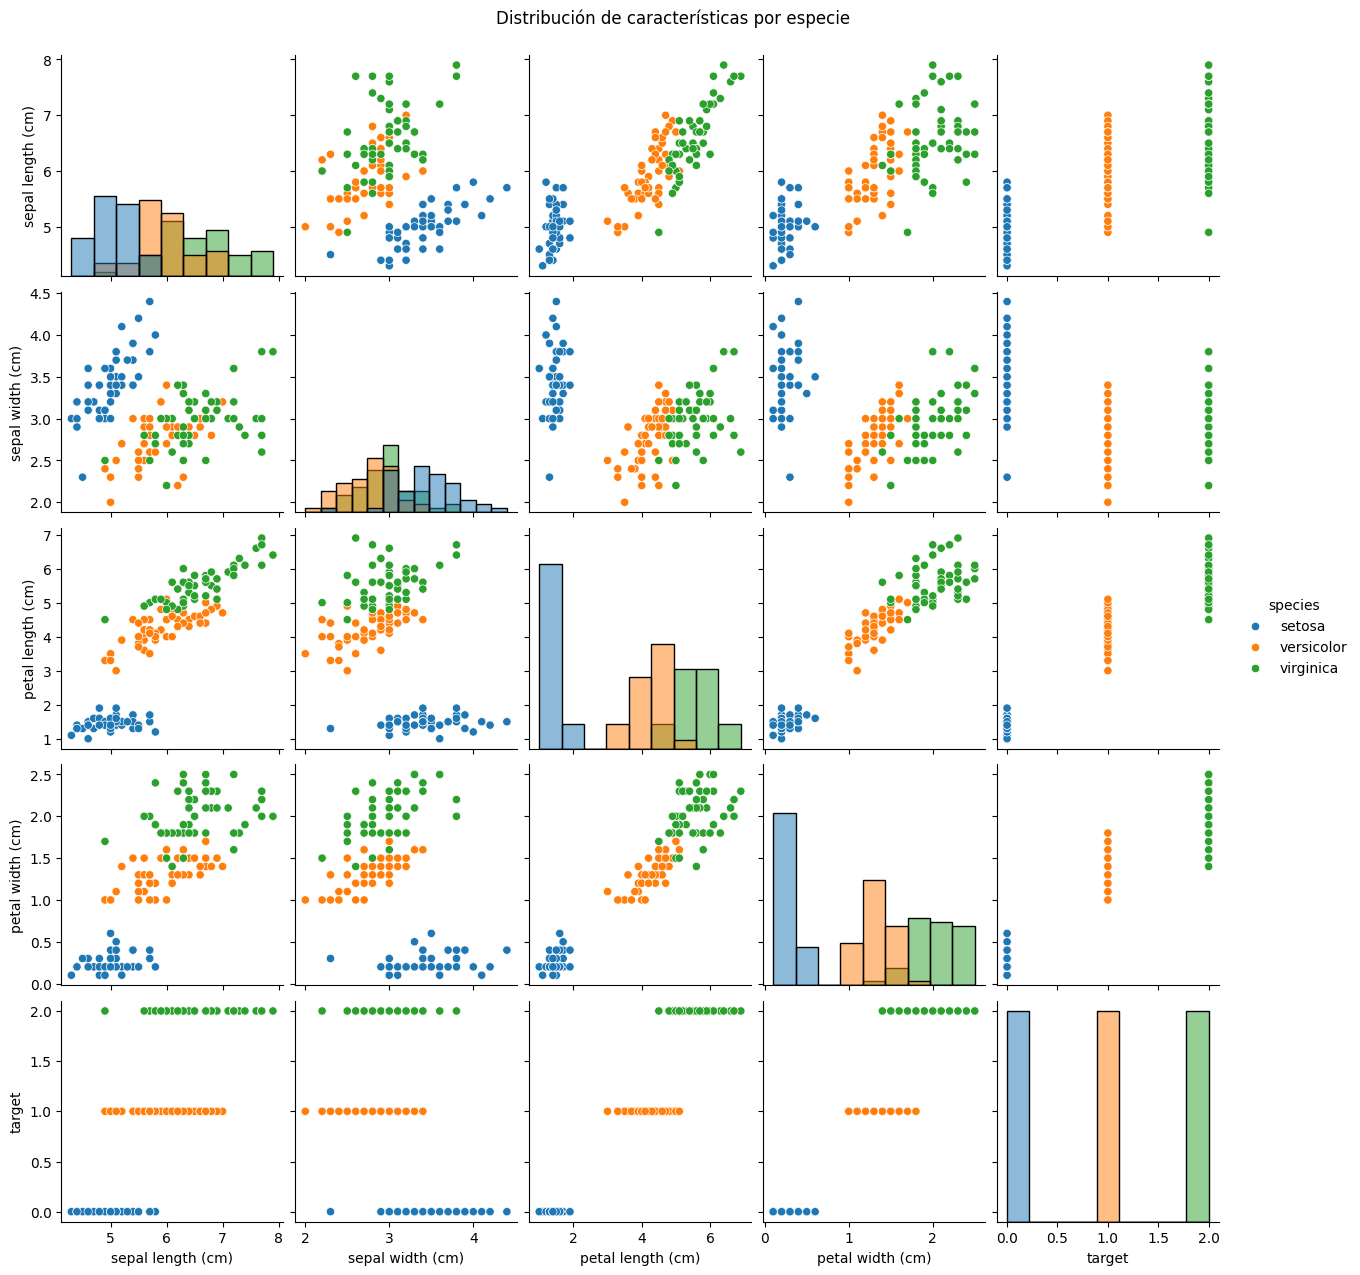

In [14]:
import seaborn as sns
sns.pairplot(df, hue='species', diag_kind='hist')
plt.suptitle('Distribución de características por especie', y=1.02)
plt.show()

## El perceptrón: la unidad básica de una red neuronal artificial
El perceptrón es el modelo más simple de una neurona artificial. Recibe varias entradas, les asigna pesos, suma los resultados y aplica una función de activación.

**Fórmula del perceptrón:**
$$ y = f\left(\sum_{i=1}^n w_i x_i + b \right) $$
donde:
- $x_i$ son las entradas
- $w_i$ son los pesos
- $b$ es el sesgo
- $f$ es la función de activación (por ejemplo, sigmoide, ReLU, etc.)

In [15]:
# Ejemplo práctico: Perceptrón para clasificación binaria
from sklearn.linear_model import Perceptron
import numpy as np

# Usamos solo dos clases del dataset Iris para ilustrar el perceptrón
X_bin = df[df['target'] != 2][iris.feature_names].values
y_bin = df[df['target'] != 2]['target'].values

percep = Perceptron(max_iter=1000, random_state=42)
percep.fit(X_bin, y_bin)
y_pred_percep = percep.predict(X_bin)

print('Exactitud del perceptrón en clasificación binaria:', np.mean(y_pred_percep == y_bin))

Exactitud del perceptrón en clasificación binaria: 1.0


## 3. Preprocesamiento
Dividimos los datos en entrenamiento y prueba, y normalizamos las características.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Entrenamiento de modelos
Entrenaremos dos modelos: Regresión Logística y una Red Neuronal simple.

In [17]:
# Regresión Logística
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=200)
logreg.fit(X_train_scaled, y_train)

# Red Neuronal simple (MLP)
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(8,), activation='relu', max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(8,), max_iter=500, random_state=42)

## 5. Evaluación de modelos
Comparamos el desempeño de ambos modelos en el conjunto de prueba.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, log_loss


y_pred_logreg = logreg.predict(X_test_scaled)
y_pred_mlp = mlp.predict(X_test_scaled)

# Evaluación de modelos: comentarios sobre cada métrica

# Exactitud (accuracy): proporción de predicciones correctas sobre el total.
print('Exactitud Regresión Logística:', accuracy_score(y_test, y_pred_logreg))
print('Exactitud Red Neuronal:', accuracy_score(y_test, y_pred_mlp))

# classification_report: muestra precisión, recall y F1-score por clase.
print('Reporte de clasificación (Red Neuronal):')
print(classification_report(y_test, y_pred_mlp, target_names=iris.target_names))

# Matriz de confusión: muestra los aciertos y errores por clase.
print('Matriz de confusión (Red Neuronal):')
print(confusion_matrix(y_test, y_pred_mlp))

# Balanced Accuracy: útil si las clases están desbalanceadas.
print('Balanced Accuracy:', balanced_accuracy_score(y_test, y_pred_mlp))

# Cohen Kappa: mide el acuerdo entre predicción y verdad, corrigiendo el azar.
print('Cohen Kappa:', cohen_kappa_score(y_test, y_pred_mlp))

# Matthews Correlation Coefficient: métrica robusta para clasificación multiclase.
print('Matthews Corrcoef:', matthews_corrcoef(y_test, y_pred_mlp))

# Log Loss: penaliza las predicciones menos seguras, útil para modelos probabilísticos.
y_prob_mlp = mlp.predict_proba(X_test_scaled)
print('Log Loss:', log_loss(y_test, y_prob_mlp))

# Analiza todas las métricas en conjunto. La exactitud muestra el desempeño general,
# la matriz de confusión y el classification_report permiten identificar clases difíciles.
# Balanced accuracy, Cohen Kappa y MCC son útiles si hay desbalance o quieres una visión más robusta.
# Log Loss es relevante si el modelo entrega probabilidades y quieres penalizar predicciones

Exactitud Regresión Logística: 0.9111111111111111
Exactitud Red Neuronal: 0.8222222222222222
Reporte de clasificación (Red Neuronal):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.73      0.73      0.73        15
   virginica       0.73      0.73      0.73        15

    accuracy                           0.82        45
   macro avg       0.82      0.82      0.82        45
weighted avg       0.82      0.82      0.82        45

Matriz de confusión (Red Neuronal):
[[15  0  0]
 [ 0 11  4]
 [ 0  4 11]]
Balanced Accuracy: 0.8222222222222223
Cohen Kappa: 0.7333333333333334
Matthews Corrcoef: 0.7333333333333333
Log Loss: 0.39082492059845464


: 

## 6. Explicación de conceptos clave
- **Función de activación:** En la red neuronal usamos ReLU en la capa oculta y Softmax en la salida para clasificación multiclase.
- **Función de pérdida:** El modelo minimiza la entropía cruzada categórica durante el entrenamiento.
- **Forward pass:** Los datos pasan por las capas, se aplican pesos, sesgos y funciones de activación.
- **Backpropagation:** El error se retropropaga y los pesos se ajustan para mejorar la predicción.

## Problemas que se pueden resolver con redes neuronales artificiales
Las redes neuronales se utilizan en muchos campos, por ejemplo:
- **Clasificación:** detección de spam, reconocimiento de imágenes, diagnóstico médico.
- **Regresión:** predicción de precios, análisis financiero.
- **Procesamiento de imágenes:** reconocimiento facial, segmentación de imágenes médicas.
- **Procesamiento de lenguaje natural (NLP):** traducción automática, análisis de sentimientos, chatbots.
- **Series temporales y predicciones:** predicción del clima, detección de fraudes.
- **Sistemas de recomendación:** sugerencias de productos en plataformas como Netflix, Amazon o Spotify.
- **Control y automatización:** robótica, conducción autónoma, sistemas industriales.